In [1]:
import os
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel


print("All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
MAX_SEQ_LEN = 512
BATCH_SIZE = 32
model_names = [
    "abhinand/MedEmbed-large-v0.1",
    "medicalai/ClinicalBERT",
    "microsoft/BiomedVLP-CXR-BERT-specialized"
]
# Set device
# Set this before importing torch (restart kernel after changing)
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import torch
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
# ===============================
# 2️⃣ Load models
# ===============================
print("Loading models...")
tokenizers, models = [], []
for name in model_names:
    print(f"  - {name}")
    tokenizer = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
    model = AutoModel.from_pretrained(name, trust_remote_code=True).eval().to(device)
    tokenizers.append(tokenizer)
    models.append(model)

max_dim = max(m.config.hidden_size for m in models)

# ===============================
# 3️⃣ Utility functions
# ===============================
def mean_pooling(output, mask):
    embeddings = output.last_hidden_state  # [B, seq_len, hidden]
    mask = mask.unsqueeze(-1).float()
    summed = torch.sum(embeddings * mask, dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts

def pad_tokens(tokens, target_len=MAX_SEQ_LEN):
    seq_len, dim = tokens.shape
    if seq_len < target_len:
        pad = torch.zeros(target_len - seq_len, dim, device=tokens.device)
        tokens = torch.cat([tokens, pad], dim=0)
    else:
        tokens = tokens[:target_len]
    return tokens


def encode_batch_multi(text_batch):
    pooled_list = []
    token_list = []

    for tokenizer, model in zip(tokenizers, models):
        inputs = tokenizer(
            text_batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SEQ_LEN
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            output = model(**inputs)

        # Pooled embeddings
        pooled = mean_pooling(output, inputs['attention_mask'])  # [B, hidden]
        pooled_list.append(pooled)

        # Token-level embeddings
        hidden = output.last_hidden_state  # [B, seq_len, hidden]
        batch_tokens = []
        for h in hidden:
            h = pad_tokens(h, MAX_SEQ_LEN)
            pad_size = max_dim - h.size(-1)
            if pad_size > 0:
                h = torch.nn.functional.pad(h, (0, pad_size), value=0)
            batch_tokens.append(h.unsqueeze(0))
        batch_tokens = torch.cat(batch_tokens, dim=0)
        token_list.append(batch_tokens)

    # Concatenate across models
    c_vec = torch.cat(pooled_list, dim=-1).squeeze(dim=0)  # [B, total_dim]
    c_ctx = torch.cat(token_list, dim=1).squeeze(dim=0)   # [B, num_models*512, max_dim]
    return c_vec.cpu().numpy(), c_ctx.cpu().numpy()




/home/sina/miniconda3/envs/vlm3d/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!
PyTorch version: 2.6.0+cu124
CUDA available: True
cuda:0 NVIDIA H100 NVL
Loading models...
  - abhinand/MedEmbed-large-v0.1
  - medicalai/ClinicalBERT
  - microsoft/BiomedVLP-CXR-BERT-specialized


In [2]:
finding= "Trachea and both main bronchi are open. No occlusive pathology was detected in the trachea and both main bronchi. Peripheral and central consolidations and areas of ground glass are observed in the upper and lower lobes of both lungs and the middle lobe of the right lung. When evaluated together with the clinical information of the patient, these appearances were evaluated primarily in favor of viral pneumonia. The findings described in Covid-19 pneumonia are frequently observed. No mass was detected in both lungs. Mediastinal structures cannot be evaluated optimally because contrast material is not given. As far as can be observed: Heart contour and size are normal. There is no pleural or pericardial effusion. The widths of the mediastinal main vascular structures are normal. No pathologically enlarged lymph nodes were detected in the mediastinum and hilar regions. No pathological wall thickness increase was observed in the esophagus within the sections. No upper abdominal free fluid-collection was detected in the sections. No enlarged lymph nodes in pathological dimensions were detected. In the upper abdominal organs within the sections, there is no mass with distinguishable borders as far as it can be observed within the borders of non-enhanced CT. Thoracic vertebral corpus heights, alignments and densities are normal. Intervertebral disc distances are preserved. The neural foramina are open. No lytic-destructive lesions were detected in the bone structures within the sections."
impression= "Findings consistent with viral pneumonia in both lungs."


In [3]:

original_spacing = (0.40625, 0.40625, 1.5)
original_size = (1024, 1024, 231)
print(f"Finding text: {finding}")
print(f"Impression text: {impression}")
print(f"Original spacing: {original_spacing}")
print(f"Original size: {original_size}")
synth_size = (480, 480, 256)
synth_spacing = np.array(original_spacing) * np.array(original_size) / np.array(synth_size)
print(f"Synthesized spacing: {synth_spacing}")

Finding text: Trachea and both main bronchi are open. No occlusive pathology was detected in the trachea and both main bronchi. Peripheral and central consolidations and areas of ground glass are observed in the upper and lower lobes of both lungs and the middle lobe of the right lung. When evaluated together with the clinical information of the patient, these appearances were evaluated primarily in favor of viral pneumonia. The findings described in Covid-19 pneumonia are frequently observed. No mass was detected in both lungs. Mediastinal structures cannot be evaluated optimally because contrast material is not given. As far as can be observed: Heart contour and size are normal. There is no pleural or pericardial effusion. The widths of the mediastinal main vascular structures are normal. No pathologically enlarged lymph nodes were detected in the mediastinum and hilar regions. No pathological wall thickness increase was observed in the esophagus within the sections. No upper abdomin

In [4]:
c_vec_f, _ = encode_batch_multi(finding)
c_vec_i, _ = encode_batch_multi(impression)

context_f = torch.from_numpy(c_vec_f) 
context_i = torch.from_numpy(c_vec_i)
# spacing = torch.tensor([0.889, 0.889, 1.498]) * 100
spacing = torch.from_numpy(synth_spacing) * 100
print(f"findings shape: {context_f.shape}, impressions shape: {context_i.shape}")
print(f"spacing: {spacing}")

# text = train_data["Impressions_EN_embeddings"].to(device)  # (B, L, D) or (B, 1, D)
context_f = context_f.unsqueeze(0).unsqueeze(0)
                      # promote single token to sequence dim
context_i = context_i.unsqueeze(0).unsqueeze(0)
spacing_tensor = spacing.unsqueeze(0).half()  # (1, 1, 3)
### concatenate context embeddings
context = torch.cat((context_f, context_i), dim=1) # Conc
print(f"Concatenated context shape: {context.shape}")


findings shape: torch.Size([2560]), impressions shape: torch.Size([2560])
spacing: tensor([ 86.6667,  86.6667, 135.3516], dtype=torch.float64)
Concatenated context shape: torch.Size([1, 2, 2560])


In [5]:
print(context.min(), context.max(), context.mean(), context.std())


tensor(-2.2106) tensor(3.4656) tensor(0.0036) tensor(0.3973)


In [7]:
import os
import torch
import json
import logging
from types import SimpleNamespace
from src.maisi.scripts.diff_model_infer_vlm3D import (
    load_config,
    initialize_distributed,
    setup_logging,
    set_random_seed,
    load_models,
    prepare_tensors,
    prepare_context_tensor,
    # run_inference,
    save_image,
)


In [8]:
# Paths to your config files
work_dir = "./vlm3D_work_dir"
env_config_path = os.path.join(work_dir, "environment_maisi_diff_model_vlm3D_FI_2560_multi.json")
model_config_path = os.path.join(work_dir, "config_maisi_diff_model_vlm3D.json")
model_def_path = os.path.join(work_dir, "config_maisi_2560.json")


args = load_config(env_config_path, model_config_path, model_def_path)


In [9]:
args.model_filename = "diff_unet_ckpt_FI_2560_multi_best.pt"


In [10]:
# Initialize distributed training with single GPU (for notebook)
num_gpus = 1

logger = setup_logging("test_infer")

# Set random seed
random_seed = set_random_seed( 2045)
print(f"using seeed: {random_seed}")


using seeed: 2045


In [11]:
autoencoder, unet, scale_factor = load_models(args, device, logger)
print(f"Loaded models. Scale factor: {scale_factor}")


[2025-10-06 15:23:48.782][ INFO](test_infer) - checkpoints ./vlm3D_work_dir/models/diff_unet_ckpt_FI_2560_multi_best.pt loaded.
[2025-10-06 15:23:48.787][ INFO](test_infer) - scale_factor -> 1.050519347190857.
[2025-10-06 15:23:48.788][ INFO](test_infer) - epoch -> 77.


Loaded models. Scale factor: 1.050519347190857


In [12]:
top_region_index_tensor = np.array(args.diffusion_unet_inference["top_region_index"]).astype(float) * 1e2
bottom_region_index_tensor = np.array(args.diffusion_unet_inference["bottom_region_index"]).astype(float) * 1e2
top_region_index_tensor = torch.from_numpy(top_region_index_tensor[np.newaxis, :]).half().to(device)
bottom_region_index_tensor = torch.from_numpy(bottom_region_index_tensor[np.newaxis, :]).half().to(device)
modality_tensor = args.diffusion_unet_inference["modality"] * torch.ones(
        (len(spacing_tensor)), dtype=torch.long
    ).to(device)

print("top_region_index_tensor:", top_region_index_tensor.shape)
print("spacing_tensor:", spacing_tensor.shape)
print("spacing_tensor:", spacing_tensor)
print("modality_tensor:", modality_tensor)



top_region_index_tensor: torch.Size([1, 4])
spacing_tensor: torch.Size([1, 3])
spacing_tensor: tensor([[ 86.6875,  86.6875, 135.3750]], dtype=torch.float16)
modality_tensor: tensor([1], device='cuda:0')


In [13]:
import argparse
import json
import logging
import os
import random
from datetime import datetime

import nibabel as nib
import numpy as np
import torch
import torch.distributed as dist
from monai.inferers import sliding_window_inference
from monai.inferers.inferer import SlidingWindowInferer
from monai.networks.schedulers import RFlowScheduler
from monai.utils import set_determinism
from tqdm import tqdm

# from src.maisi.scripts.sample import ReconModel, check_input
from src.maisi.scripts.utils import define_instance, dynamic_infer

class ReconModel(torch.nn.Module):
    """
    A PyTorch module for reconstructing images from latent representations.

    Attributes:
        autoencoder: The autoencoder model used for decoding.
        scale_factor: Scaling factor applied to the input before decoding.
    """

    def __init__(self, autoencoder, scale_factor):
        super().__init__()
        self.autoencoder = autoencoder
        self.scale_factor = scale_factor

    def forward(self, z):
        """
        Decode the input latent representation to an image.

        Args:
            z (torch.Tensor): The input latent representation.

        Returns:
            torch.Tensor: The reconstructed image.
        """
        recon_pt_nda = self.autoencoder.decode_stage_2_outputs(z.float() / self.scale_factor.float())
        return recon_pt_nda
def run_inference(
    args: argparse.Namespace,
    device: torch.device,
    autoencoder: torch.nn.Module,
    unet: torch.nn.Module,
    scale_factor: float,
    top_region_index_tensor: torch.Tensor,
    bottom_region_index_tensor: torch.Tensor,
    spacing_tensor: torch.Tensor,
    modality_tensor: torch.Tensor,
    context_tensor: torch.Tensor,
    output_size: tuple,
    divisor: int,
    logger: logging.Logger,
    cfg_scale: None
) -> np.ndarray:
    torch.cuda.empty_cache()
    
    include_body_region = unet.include_top_region_index_input
    include_modality = unet.num_class_embeds is not None

    noise_shape = (
        1,
        args.latent_channels,
        output_size[0] // divisor,
        output_size[1] // divisor,
        output_size[2] // divisor,
    )
    noise = torch.randn(noise_shape, dtype=torch.float16, device=device)
    logger.info(f"Noise shape: {noise.shape}, dtype: {noise.dtype}, device: {noise.device}")

    image = noise
    noise_scheduler = define_instance(args, "noise_scheduler")

    if isinstance(noise_scheduler, RFlowScheduler):
        noise_scheduler.set_timesteps(
            num_inference_steps=args.diffusion_unet_inference["num_inference_steps"],
            input_img_size_numel=torch.prod(torch.tensor(noise.shape[2:])),
        )
    else:
        noise_scheduler.set_timesteps(
            num_inference_steps=args.diffusion_unet_inference["num_inference_steps"]
        )

    recon_model = ReconModel(autoencoder=autoencoder, scale_factor=scale_factor).to(device)
    autoencoder.eval()
    unet.eval()

    all_timesteps = noise_scheduler.timesteps
    all_next_timesteps = torch.cat((all_timesteps[1:], torch.tensor([0], dtype=all_timesteps.dtype)))
    progress_bar = tqdm(zip(all_timesteps, all_next_timesteps), total=len(all_timesteps))
 
    try:
        with torch.no_grad(), torch.amp.autocast("cuda", enabled=True):
            for t, next_t in progress_bar:
                unet_inputs = {
                    "x": image,
                    "timesteps": t.unsqueeze(0).to(device),
                    "spacing_tensor": spacing_tensor.to(device),
                }

                if context_tensor is not None:
                    unet_inputs["context"] = context_tensor
                if include_body_region:
                    unet_inputs["top_region_index_tensor"] = top_region_index_tensor
                    unet_inputs["bottom_region_index_tensor"] = bottom_region_index_tensor
                if include_modality:
                    unet_inputs["class_labels"] = modality_tensor

                # noise_pred_cond = unet(**unet_inputs)

                if cfg_scale is not None:
                    if not torch.is_tensor(cfg_scale):
                        cfg_scale = torch.tensor(cfg_scale, dtype=image.dtype, device=image.device)
                    else:
                        cfg_scale = cfg_scale.clone().detach().to(dtype=image.dtype, device=image.device)
                    # Duplicate inputs
                    unet_inputs_cond = unet_inputs
                    unet_inputs_uncond = {
                        k: (torch.zeros_like(v) if k == "context" else v)
                        for k, v in unet_inputs.items()
                    }

                    # Combine in a single batch
                    x_in = torch.cat([unet_inputs_cond["x"], unet_inputs_uncond["x"]], dim=0)
                    t_in = torch.cat([unet_inputs_cond["timesteps"], unet_inputs_uncond["timesteps"]], dim=0)
                    context_in = torch.cat([unet_inputs_cond["context"], unet_inputs_uncond["context"]], dim=0)

                    unet_inputs_batch = {
                        "x": x_in.to(device),
                        "timesteps": t_in.to(device),
                        "spacing_tensor": torch.cat([spacing_tensor.to(device), spacing_tensor.to(device)], dim=0),
                        "context": context_in.to(device),
                    }
                    if include_body_region:
                        unet_inputs_batch["top_region_index_tensor"] = torch.cat([top_region_index_tensor.to(device)]*2, dim=0)
                        unet_inputs_batch["bottom_region_index_tensor"] = torch.cat([bottom_region_index_tensor.to(device)]*2, dim=0)
                    if include_modality:
                        unet_inputs_batch["class_labels"] = torch.cat([modality_tensor.to(device)]*2, dim=0)


                    noise_pred = unet(**unet_inputs_batch)
                    noise_pred_cond, noise_pred_uncond = noise_pred.chunk(2)
                    model_output = noise_pred_uncond + cfg_scale * (noise_pred_cond - noise_pred_uncond)
                else:
                    model_output = unet(**unet_inputs)

                
                
                if isinstance(noise_scheduler, RFlowScheduler):
                    image, _ = noise_scheduler.step(model_output, t, image, next_t)
                else:
                    image, _ = noise_scheduler.step(model_output, t, image)

                # Actively free up unused memory
                torch.cuda.empty_cache()
        with torch.no_grad(), torch.amp.autocast("cuda", enabled=True):
            # Final decoding
            inferer = SlidingWindowInferer(
                roi_size=[80, 80, 80],
                sw_batch_size=1,
                progress=True,
                mode="gaussian",
                overlap=0.4,
                sw_device=device,
                device=device,
            )
            synthetic_images = dynamic_infer(inferer, recon_model.float(), image.float())
        data = synthetic_images.squeeze().cpu().detach().numpy()

        # Rescale and clip
        a_min, a_max, b_min, b_max = -1000, 1000, 0, 1
        data = (data - b_min) / (b_max - b_min) * (a_max - a_min) + a_min
        return np.clip(data, a_min, a_max).astype(np.int16)

    except RuntimeError as e:
        if "out of memory" in str(e):
            logger.error("CUDA out of memory during inference. Consider reducing `dim`, `latent_channels`, or increasing ROI overlap.")
            print(torch.cuda.memory_summary())
        raise e


In [14]:
output_size = (480, 480, 256)
cfg_scale = None
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
args.diffusion_unet_inference["num_inference_steps"] = 500
num_downsample_level = max(
    1,
    len(args.diffusion_unet_def["num_channels"]) 
    if isinstance(args.diffusion_unet_def["num_channels"], list)
    else len(args.diffusion_unet_def["attention_levels"])
)
divisor = 2 ** (num_downsample_level - 2)
context_tensor = context.to(device)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
# Run inference
data = run_inference(
    args,
    device,
    autoencoder,
    unet,
    scale_factor,
    top_region_index_tensor,
    bottom_region_index_tensor,
    spacing_tensor,
    modality_tensor,
    context_tensor,
    output_size,
    divisor,
    logger,
    cfg_scale=cfg_scale
)
print("Output shape:", data.shape)


[2025-10-06 15:24:03.710][ INFO](test_infer) - Noise shape: torch.Size([1, 4, 120, 120, 64]), dtype: torch.float16, device: cuda:0
100%|██████████| 4/4 [00:04<00:00,  1.03s/it]


Output shape: (480, 480, 256)


In [15]:


import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

def show_nifti_slices(nifti_path, slice_indices=None, figsize=(15, 5), cmap='gray'):
    """
    Display orthogonal slices from a NIfTI file.

    Args:
        nifti_path (str): Path to the NIfTI (.nii or .nii.gz) file.
        slice_indices (tuple or None): (axial, coronal, sagittal) slice indices.
        figsize (tuple): Figure size for matplotlib.
        cmap (str): Colormap for visualization.
    """
    img = nib.load(nifti_path)
    data = img.get_fdata()

    # Automatically choose central slices if not provided
    z, y, x = data.shape
    if slice_indices is None:
        slice_indices = (z // 2, y // 2, x // 2)

    axial_slice = data[slice_indices[0], :, :]
    coronal_slice = data[:, slice_indices[1], :]
    sagittal_slice = data[:, :, slice_indices[2]]

    fig, axs = plt.subplots(1, 3, figsize=figsize)
    axs[0].imshow(np.rot90(axial_slice), cmap=cmap)
    # axs[0].set_title(f'Axial slice {slice_indices[0]}')
    axs[1].imshow(np.rot90(coronal_slice), cmap=cmap)
    # axs[1].set_title(f'Coronal slice {slice_indices[1]}')
    axs[2].imshow(np.rot90(sagittal_slice), cmap=cmap)
    # axs[2].set_title(f'Sagittal slice {slice_indices[2]}')
    for ax in axs:
        ax.axis('off')
    plt.tight_layout()
    plt.show()



In [16]:
from datetime import datetime
output_prefix = args.output_prefix
out_spacing = tuple(args.diffusion_unet_inference["spacing"])
timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
output_path = f"{args.output_dir}/{output_prefix}_{timestamp}_seed_{random_seed}_inference_CFG{str(cfg_scale)}.nii.gz"
save_image(data, output_size, out_spacing, output_path, logger)


[2025-10-06 15:25:23.534][ INFO](test_infer) - Saved ./vlm3D_work_dir/predictions/unet_3d_20251006152521_seed_2045_inference_CFGNone.nii.gz.


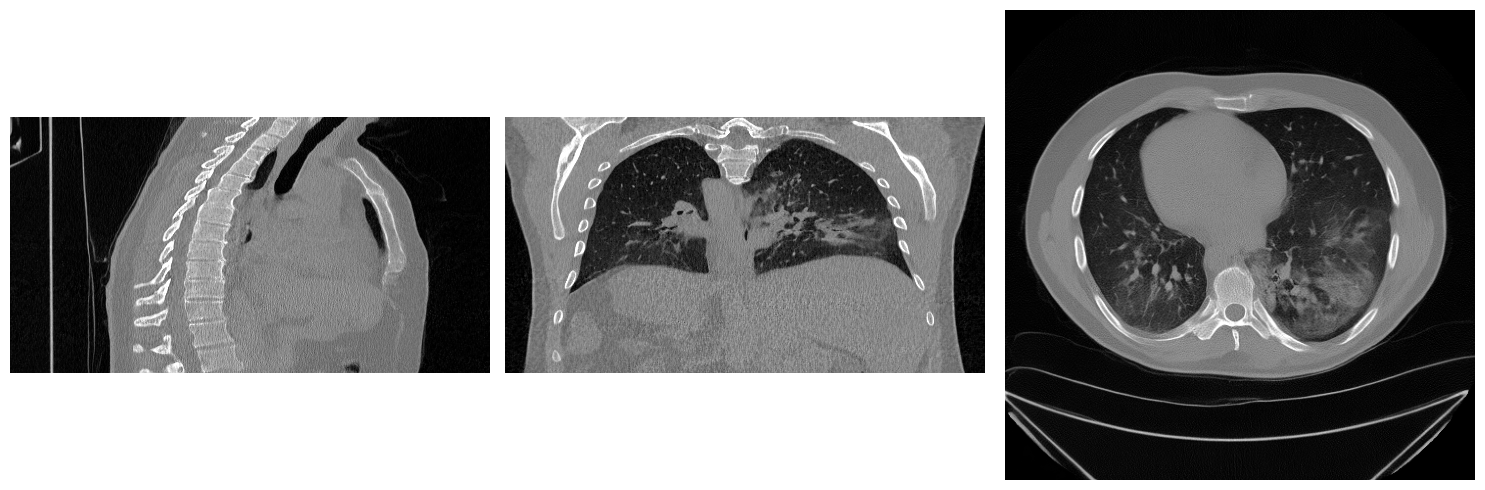

In [18]:
show_nifti_slices(output_path, slice_indices=(data.shape[0] // 2, data.shape[1] // 2, data.shape[2] // 2), figsize=(15, 5), cmap='gray')